# 1. Introducción: predicción de la progresión de la diabetes

### Objetivo
Construir un modelo de regresión que prediga cómo avanza la diabetes de un paciente un año después de la primera medición, a partir de datos numéricos como la edad, el índice de masa corporal (IMC) o la tensión arterial.

### Tipo de problema
Es un problema de **regresión**: el valor que queremos predecir es un número continuo, una medida de la progresión de la enfermedad.

### Punto de partida
Este notebook es la fase exploratoria: entender los datos, comprobar su calidad, limpiarlos y probar unos modelos sencillos.

### Camino hacia MLOps
Después, este código se lleva a scripts reutilizables dentro del repositorio:
- **Extracción, validación y limpieza** de los datos (`src/data/`)
- **Entrenamiento con seguimiento en MLflow** (`src/models/`)
- **Registro del modelo y elección del modelo campeón** (`src/models/`)
- **API con FastAPI** para servir predicciones (`app/`)
- **CI/CD con GitHub Actions** para ejecutar el pipeline automáticamente

## 2. Entorno e importaciones

Usamos las librerías habituales para manipular datos, hacer gráficos y entrenar modelos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Estilo de los gráficos
sns.set_theme(style="whitegrid")

## 3. Carga del dataset

Usamos el dataset Diabetes que incluye scikit-learn, con los **valores reales sin escalar** (`scaled=False`): la edad en años, el IMC, la tensión, etc. Así los datos se entienden mejor y es más fácil detectar valores imposibles.

In [2]:
# Carga el dataset Diabetes con los valores reales (sin escalar)
diabetes = load_diabetes(as_frame=True, scaled=False)
df = diabetes.frame

print(f"Dimensiones del dataset: {df.shape}")
print(f"Columnas: {df.columns.tolist()}")
display(df.head())

Dimensiones del dataset: (442, 11)
Columnas: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


## 4. Exploración básica de los datos

Revisamos la calidad y la distribución de los datos: tipos, nulos, duplicados, estadísticas básicas y correlación de cada variable con el objetivo.

Tipos de datos y valores nulos:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Estadísticas básicas:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000
mean,48.518100,1.468326,26.375792,94.647014,189.140271,115.439140,49.788462,4.070249,4.641411,91.260181,152.133484
std,13.109028,0.499561,4.418122,13.831283,34.608052,30.413081,12.934202,1.290450,0.522391,11.496335,77.093005
min,19.000000,1.000000,18.000000,62.000000,97.000000,41.600000,22.000000,2.000000,3.258100,58.000000,25.000000
25%,38.250000,1.000000,23.200000,84.000000,164.250000,96.050000,40.250000,3.000000,4.276700,83.250000,87.000000
50%,50.000000,1.000000,25.700000,93.000000,186.000000,113.000000,48.000000,4.000000,4.620050,91.000000,140.500000
75%,59.000000,2.000000,29.275000,105.000000,209.750000,134.500000,57.750000,5.000000,4.997200,98.000000,211.500000
max,79.000000,2.000000,42.200000,133.000000,301.000000,242.400000,99.000000,9.090000,6.107000,124.000000,346.000000



Filas duplicadas: 0


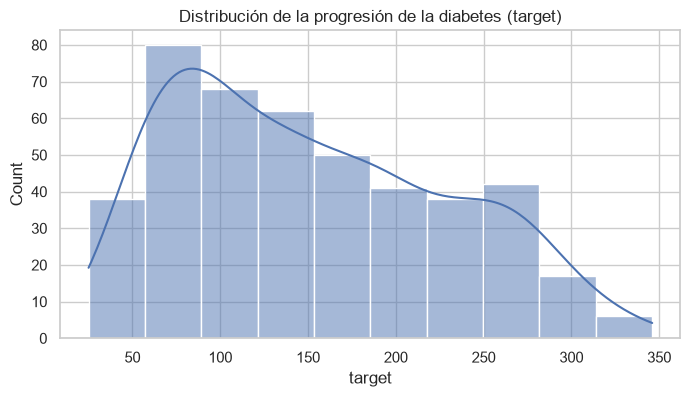


Correlación con el objetivo:
target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


In [3]:
# Tipos de datos y valores nulos
print("Tipos de datos y valores nulos:")
df.info()

# Estadísticas básicas
print("\nEstadísticas básicas:")
display(df.describe())

# Filas duplicadas
print(f"\nFilas duplicadas: {df.duplicated().sum()}")

# Distribución del valor objetivo
plt.figure(figsize=(8, 4))
sns.histplot(df["target"], kde=True)
plt.title("Distribución de la progresión de la diabetes (target)")
plt.show()

# Correlación de cada variable con el objetivo
correlations = df.corr()["target"].sort_values(ascending=False)
print("\nCorrelación con el objetivo:")
print(correlations)

## 5. Extracción de los datos

Guardamos los datos tal como llegan en `data/raw/diabetes.csv`. Esta carpeta no se modifica nunca: es la copia original.

En el repositorio, este paso lo hace el script `src/data/extract_data.py`. En un proyecto real, los datos podrían venir de una base de datos, de la nube o de una API.

In [4]:
from pathlib import Path

# Guarda los datos en bruto en data/raw, como hará el script de extracción
RAW_PATH = Path("../data/raw/diabetes.csv")
RAW_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(RAW_PATH, index=False)

print(f"Datos en bruto guardados en: {RAW_PATH.resolve()}")

Datos en bruto guardados en: C:\Users\eneko\proyectos\mlops-diabetes\data\raw\diabetes.csv


## 6. Validación de los datos

Antes de seguir, comprobamos que los datos tienen la estructura esperada:
- el dataset no está vacío,
- existe la columna objetivo (`target`),
- existen todas las columnas de entrada,
- todas las columnas son numéricas.

Si algo falla, se lanza un error y el proceso se para. Los nulos solo se cuentan, porque se tratan en la limpieza.

En el repositorio, este paso lo hace `src/data/validate_data.py`.

In [5]:
# Columnas que debe tener el dataset
FEATURES = ["age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]
TARGET = "target"

def validate_data(df):
    """Comprueba el esquema de los datos. Si algo falla, lanza un error."""
    # 1. El dataset no está vacío
    if df.empty:
        raise ValueError("El dataset está vacío.")

    # 2. Existe la columna objetivo
    if TARGET not in df.columns:
        raise ValueError(f"Falta la columna objetivo '{TARGET}'.")

    # 3. Existen todas las columnas de entrada
    missing = [col for col in FEATURES if col not in df.columns]
    if missing:
        raise ValueError(f"Faltan columnas obligatorias: {missing}")

    # 4. Todas las columnas son numéricas
    non_numeric = [col for col in FEATURES + [TARGET]
                   if not pd.api.types.is_numeric_dtype(df[col])]
    if non_numeric:
        raise ValueError(f"Columnas con tipo no numérico: {non_numeric}")

    # 5. Informa de los nulos (no para: la limpieza se encarga de ellos)
    n_nulls = int(df[FEATURES + [TARGET]].isnull().sum().sum())
    print(f"Valores nulos encontrados: {n_nulls}")

    print("✅ Validación superada")

# Valida los datos en bruto leídos del CSV, como hará el script
df_raw = pd.read_csv(RAW_PATH)
validate_data(df_raw)

Valores nulos encontrados: 0
✅ Validación superada


## 7. Limpieza de los datos

- Convertimos todo a número (lo que no se pueda convertir pasa a nulo).
- Eliminamos las filas duplicadas.
- Marcamos como nulos los valores imposibles: un sexo distinto de 1 o 2, o valores menores o iguales que 0 en el resto de columnas.
- Eliminamos las filas sin valor objetivo.
- Rellenamos los nulos con la mediana (el sexo, con el valor más frecuente).

El resultado se guarda en `data/processed/diabetes_clean.csv`. En el repositorio, este paso lo hace `src/data/clean_data.py`.

In [6]:
def clean_data(df):
    """Limpia los datos: tipos, duplicados, valores imposibles y nulos."""
    df = df.copy()
    cols = FEATURES + [TARGET]

    # 1. Asegura que todo es numérico (lo que no se pueda convertir pasa a nulo)
    for col in cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # 2. Elimina filas duplicadas
    df = df.drop_duplicates()

    # 3. Marca como nulos los valores imposibles
    df.loc[~df["sex"].isin([1, 2]), "sex"] = np.nan
    for col in cols:
        if col != "sex":
            df.loc[df[col] <= 0, col] = np.nan

    # 4. Sin valor objetivo no se puede entrenar: se elimina la fila
    df = df.dropna(subset=[TARGET])

    # 5. Rellena los nulos de las variables de entrada
    for col in FEATURES:
        if col == "sex":
            df[col] = df[col].fillna(df[col].mode()[0])   # valor más frecuente
        else:
            df[col] = df[col].fillna(df[col].median())    # mediana

    return df

# Limpia los datos validados y los guarda en data/processed
print(f"Filas antes de limpiar: {len(df_raw)}")
df_cleaned = clean_data(df_raw)
print(f"Filas después de limpiar: {len(df_cleaned)}")

PROCESSED_PATH = Path("../data/processed/diabetes_clean.csv")
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
df_cleaned.to_csv(PROCESSED_PATH, index=False)
print(f"Datos limpios guardados en: {PROCESSED_PATH.resolve()}")

Filas antes de limpiar: 442
Filas después de limpiar: 442
Datos limpios guardados en: C:\Users\eneko\proyectos\mlops-diabetes\data\processed\diabetes_clean.csv


## 8. Separación de variables y objetivo

Separamos las variables de entrada (`X`, los datos de cada paciente) del valor que queremos predecir (`y`, la progresión de la enfermedad).

In [7]:
# Separa las variables de entrada (X) del objetivo (y)
X = df_cleaned.drop(columns=["target"])
y = df_cleaned["target"]

print("X contiene los datos de los pacientes.")
print("y contiene la medida de progresión.")

X contiene los datos de los pacientes.
y contiene la medida de progresión.


## 9. División en entrenamiento y prueba

Reservamos el 20 % de los datos para evaluar el modelo con pacientes que no ha visto durante el entrenamiento. `random_state=42` hace que la división sea siempre la misma.

In [8]:
# 80 % para entrenar y 20 % para evaluar
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Muestras de entrenamiento: {len(X_train)}")
print(f"Muestras de prueba: {len(X_test)}")

Muestras de entrenamiento: 353
Muestras de prueba: 89


## 10. Entrenamiento de modelos base

Comparamos tres algoritmos de regresión sencillos con tres métricas:
- **RMSE**: el error típico de las predicciones. Penaliza más los errores grandes. Cuanto más bajo, mejor.
- **MAE**: el error medio, sin penalizar más los grandes. Cuanto más bajo, mejor.
- **R²**: qué parte de la variación del objetivo explica el modelo (1 sería perfecto).

In [9]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    results.append({"Model": name, "RMSE": rmse, "MAE": mae, "R2": r2})

results_df = pd.DataFrame(results)
display(results_df)

,Model,RMSE,MAE,R2
0,LinearRegression,53.853446,42.794095,0.452603
1,RandomForest,54.347250,44.078202,0.442518
2,GradientBoosting,53.730733,44.519359,0.455095


## 11. Resultados de la evaluación

Elegimos el mejor modelo según el RMSE, la métrica principal del proyecto.

In [10]:
# Elige el modelo con menor RMSE
best_model_row = results_df.loc[results_df["RMSE"].idxmin()]
print(f"El mejor modelo base es {best_model_row['Model']} con un RMSE de {best_model_row['RMSE']:.2f}")

El mejor modelo base es GradientBoosting con un RMSE de 53.73


## 12. Exploración sencilla de nuevas variables

Probamos si crear variables combinadas (IMC × edad, tensión × IMC y el cociente s1/s2) mejora los resultados.

In [11]:
df_eng = df_cleaned.copy()

# 1. Interacción entre IMC y edad
df_eng["bmi_age_interaction"] = df_eng["bmi"] * df_eng["age"]

# 2. Interacción entre tensión e IMC
df_eng["bp_bmi_interaction"] = df_eng["bp"] * df_eng["bmi"]

# 3. Cociente entre s1 y s2 (el 1e-9 evita dividir entre cero)
df_eng["s1_s2_ratio"] = df_eng["s1"] / (df_eng["s2"] + 1e-9)

# Vuelve a dividir los datos y a entrenar los modelos
X_eng = df_eng.drop(columns=["target"])
y_eng = df_eng["target"]
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42)

eng_results = []
for name, model in models.items():
    model.fit(X_train_e, y_train_e)
    preds = model.predict(X_test_e)
    rmse = np.sqrt(mean_squared_error(y_test_e, preds))
    eng_results.append({"Model": name + "_Eng", "RMSE": rmse})

display(pd.DataFrame(eng_results))

,Model,RMSE
0,LinearRegression_Eng,52.550878
1,RandomForest_Eng,54.070923
2,GradientBoosting_Eng,54.389481


## 13. Conclusiones

### Resultados
- Los tres modelos dan resultados muy parecidos: **RMSE ≈ 54** y **R² ≈ 0,45**. GradientBoosting queda ligeramente por delante (RMSE 53,73), pero la diferencia con LinearRegression (53,85) es muy pequeña.
- Las nuevas variables mejoran un poco la regresión lineal (el RMSE baja de 53,85 a 52,55), pero empeoran los modelos de árboles. Como la mejora es pequeña, el pipeline trabajará con las 10 variables originales.
- Usamos el **RMSE** como métrica principal porque penaliza más los errores grandes. MAE y R² sirven de apoyo.
- Los datos vienen limpios, pero la validación y la limpieza quedan preparadas para datos nuevos.

### Siguientes pasos
Llevar este trabajo a un repositorio MLOps con:
- `requirements.txt` y un entorno virtual,
- scripts de extracción, validación y limpieza,
- entrenamiento con seguimiento en MLflow,
- registro del modelo y elección del modelo campeón con un umbral de calidad,
- una API con FastAPI,
- automatización con GitHub Actions,
- un README que explique todo el proyecto.